# Лабораторная работа 01

## Первичная оценка

Достает из `ucimlrepo` таблицу с винами и их качеством `quality` по шкале от 0 до 10.
Сначала изучим структуру таблицы, пропуски, повторы, распределения и связи признаков.

In [1]:
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

wine_quality = fetch_ucirepo(id=186)
X = wine_quality.data.features
y = wine_quality.data.targets["quality"]
data = X.join(y)

### Размер и первые строки

In [2]:
print("Размер таблицы:", data.shape)
data.head()

Размер таблицы: (6497, 12)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Основные статистики

In [3]:
display(data.describe().round(3))

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


### Оценки качества

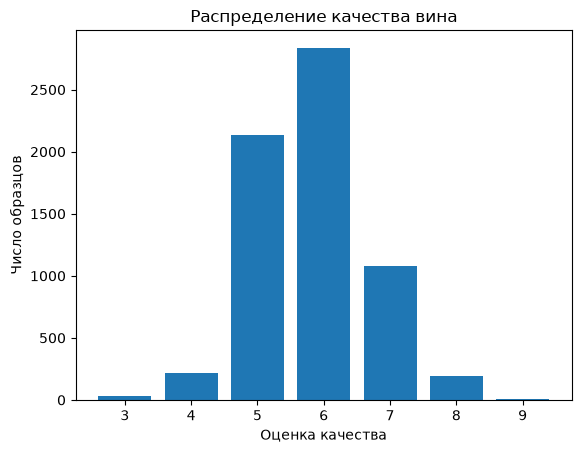

In [4]:
counts = y.value_counts().sort_index()
plt.bar(counts.index, counts.values)
plt.xlabel("Оценка качества")
plt.ylabel("Число образцов")
plt.title("Распределение качества вина")
plt.show()

Видиим, что больше всего вин имеют оценку 5 и 6.

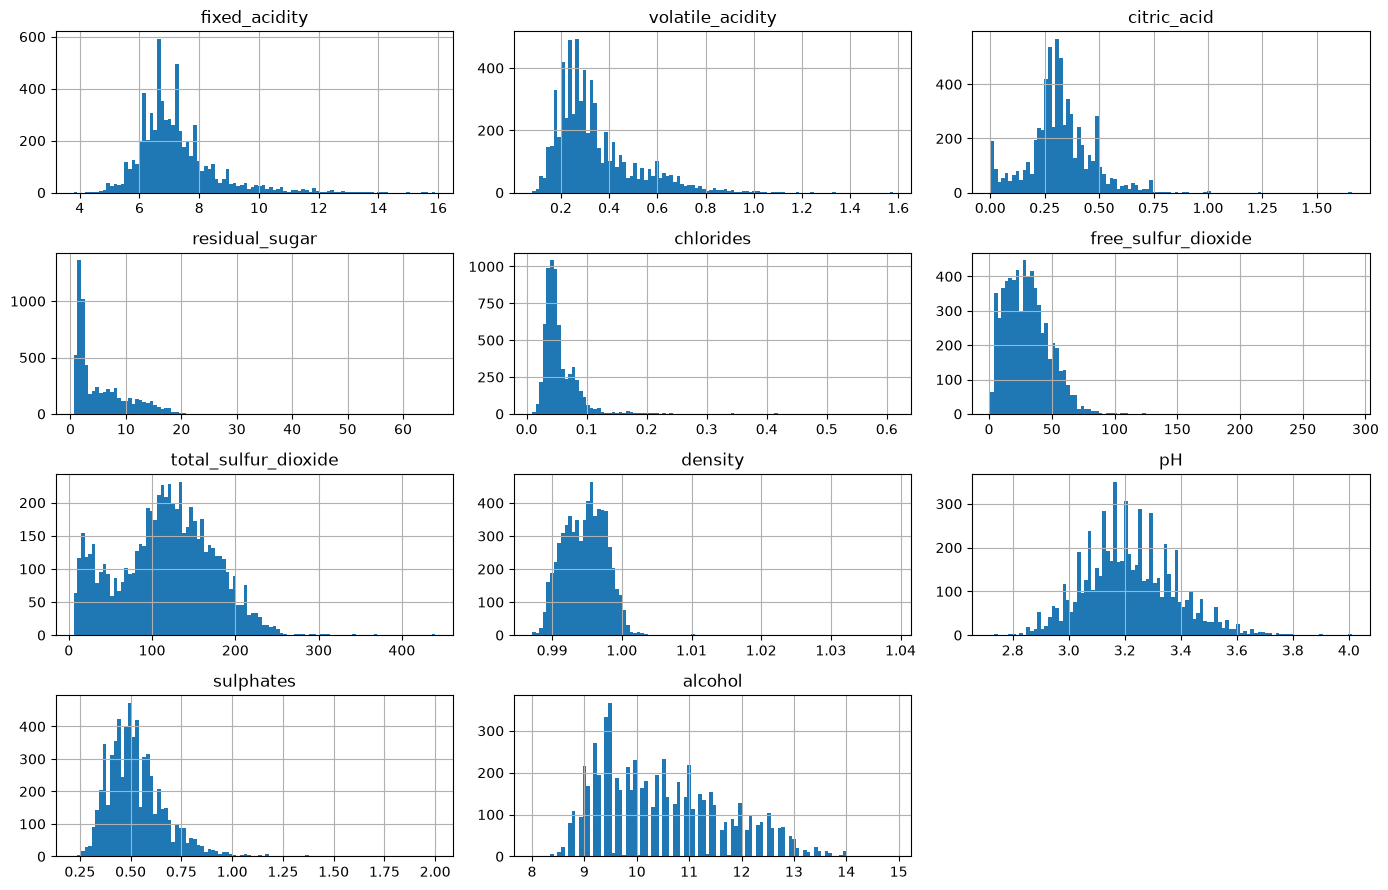

In [5]:
X.hist(bins=100, figsize=(14, 9))
plt.tight_layout()
plt.show()

Теперь усы порисуем.

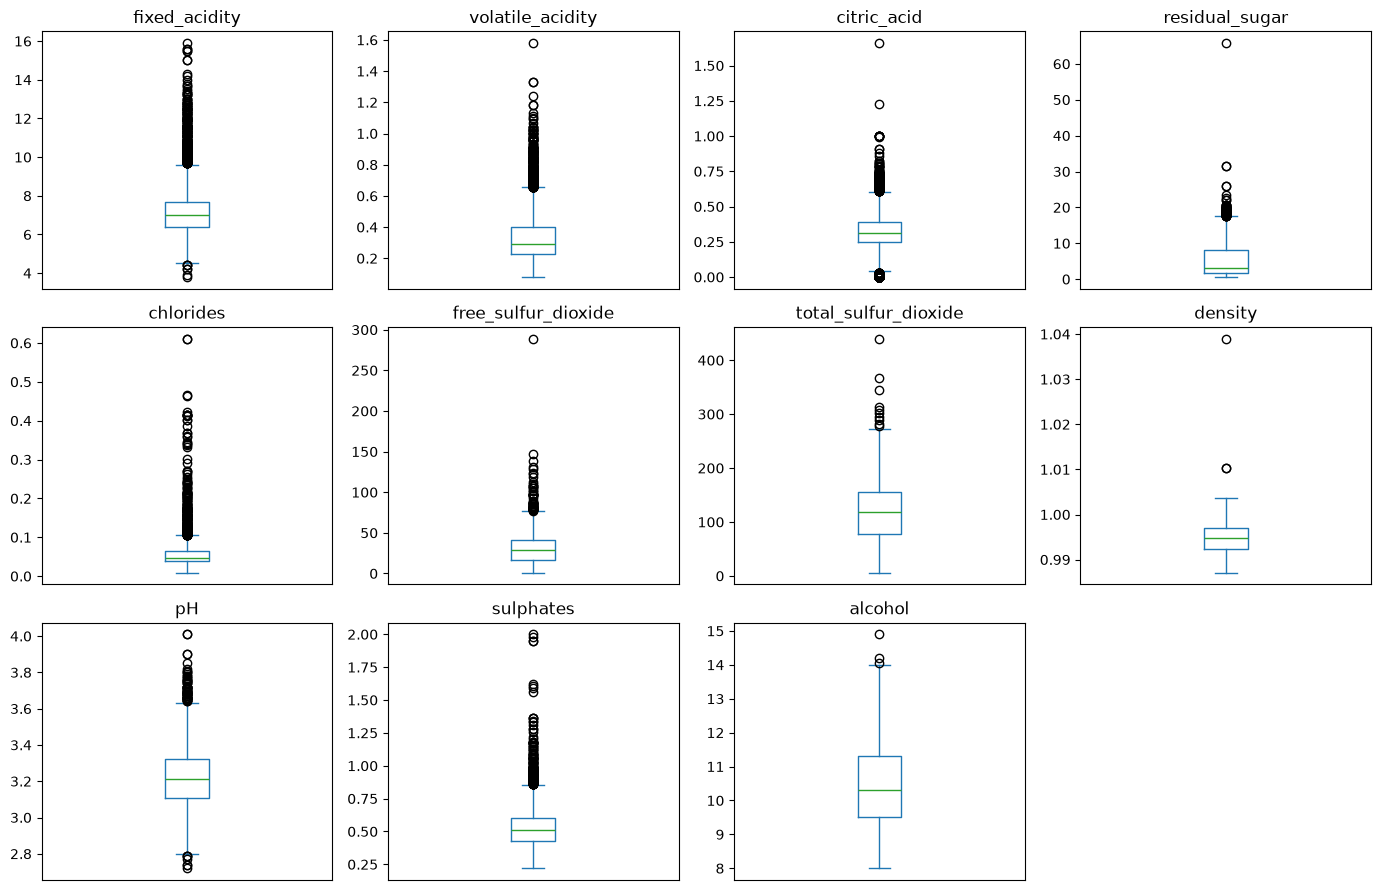

In [6]:
axes = X.plot.box(subplots=True, layout=(3, 4), figsize=(14, 9))
for column, ax in axes.items():
    ax.set_title(column)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

### Связь признаков с качеством

Корреляция показывает линейную связь с целевой переменной.

In [7]:
display(data.corr()["quality"].drop("quality").sort_values(ascending=False).round(3))

alcohol                 0.444
citric_acid             0.086
free_sulfur_dioxide     0.055
sulphates               0.038
pH                      0.020
residual_sugar         -0.037
total_sulfur_dioxide   -0.041
fixed_acidity          -0.077
chlorides              -0.201
volatile_acidity       -0.266
density                -0.306
Name: quality, dtype: float64

Отсюда видно, что модуль корреляции весомый только с уровнем алкоголя. Здесь наблюдается умеренная связь.

### Первичные выводы

- 6497 образцов, 11 входных признаков и целевая переменная `quality`.
- Пропусков нет, полных повторов строк - 1179.
- Чаще встречаются оценки качества 5 и 6.
- Самая высокая положительная корреляция с качеством - у содержания алкоголя (около 0,44).

### Обучающая и тестовая выборки

Сохраняем все наблюдения. Делим данные в пропорции 80/20, сохраняя доли оценок качества.
Цвет добавляем признаком `is_white`: 1 - белое вино, 0 - красное.

In [8]:
from sklearn.model_selection import train_test_split

X = wine_quality.data.features.copy()
X["is_white"] = (wine_quality.data.original["color"] == "white").astype(int)
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=228420, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (5197, 12)
Тестовая выборка: (1300, 12)


### Baseline: среднее качество

Для любого вина предсказываем среднее качество. Оцениваем RMSE и MAE по шести фолдам обучающей выборки: среднее каждый раз считаем только по пяти обучающим фолдам.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

baseline = DummyRegressor(strategy="mean")
scores = cross_val_score(
    baseline, X_train, y_train,
    cv=6, scoring="neg_root_mean_squared_error"
)

print(f"Baseline RMSE: {-scores.mean():.3f}")

mae_scores = cross_val_score(
    baseline, X_train, y_train,
    cv=6, scoring="neg_mean_absolute_error"
)
print(f"Baseline MAE: {-mae_scores.mean():.3f}")

Baseline RMSE: 0.873
Baseline MAE: 0.686


MSE и RMSE отличаются в подсчете. Много больших промахов в одной и той же модели могут выдать разные метрики. Так как в RMSE ошибки возводятся в квадрат перед усреднением.

### Линейная регрессия

Обучаем модель на исходных признаках. RMSE и MAE оцениваем на тех же шести фолдах обучающей выборки, что и baseline.

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

linear_rmse_scores = cross_val_score(
    model, X_train, y_train,
    cv=6, scoring="neg_root_mean_squared_error"
)
linear_mae_scores = cross_val_score(
    model, X_train, y_train,
    cv=6, scoring="neg_mean_absolute_error"
)

print(f"Linear Regression RMSE: {-linear_rmse_scores.mean():.3f}")
print(f"Linear Regression MAE: {-linear_mae_scores.mean():.3f}")

Linear Regression RMSE: 0.735
Linear Regression MAE: 0.569


Мы не используем штрафы, поэтому здесь масштабирование не нужно. Решение уравнения все равно компенсирует то, что мы намасштабируем.

### Случайный лес

Обучаем 100 деревьев на случайных выборках строк и усредняем их прогнозы. Масштабирование не требуется. Метрики считаем на тех же шести фолдах обучающей выборки.

In [11]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=100, random_state=228420, n_jobs=-1)
forest.fit(X_train, y_train)

forest_rmse_scores = cross_val_score(
    forest, X_train, y_train,
    cv=6, scoring="neg_root_mean_squared_error"
)
forest_mae_scores = cross_val_score(
    forest, X_train, y_train,
    cv=6, scoring="neg_mean_absolute_error"
)

print(f"Random Forest RMSE: {-forest_rmse_scores.mean():.3f}")
print(f"Random Forest MAE: {-forest_mae_scores.mean():.3f}")

Random Forest RMSE: 0.619
Random Forest MAE: 0.442


### Влияние цвета вина

Сравниваем модели с цветом и без него на одних и тех же строках и шести фолдах. Тестовую выборку не используем.

In [12]:
import pandas as pd
from sklearn.model_selection import cross_validate

comparison = []
for name, estimator, rmse, mae in [
    ("Линейная регрессия", model, linear_rmse_scores, linear_mae_scores),
    ("Случайный лес", forest, forest_rmse_scores, forest_mae_scores),
]:
    without_color = cross_validate(
        estimator, X_train.drop(columns="is_white"), y_train,
        cv=6, scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error"]
    )
    comparison.append({
        "Модель": name, "Цвет": "Без цвета",
        "RMSE": -without_color["test_neg_root_mean_squared_error"].mean(),
        "MAE": -without_color["test_neg_mean_absolute_error"].mean(),
    })
    comparison.append({
        "Модель": name, "Цвет": "С цветом",
        "RMSE": -rmse.mean(), "MAE": -mae.mean(),
    })

display(pd.DataFrame(comparison).round(4))

,Модель,Цвет,RMSE,MAE
0,Линейная регрессия,Без цвета,0.7361,0.5684
1,Линейная регрессия,С цветом,0.7348,0.5691
2,Случайный лес,Без цвета,0.6190,0.4425
3,Случайный лес,С цветом,0.6190,0.4424


На шести фолдах цвет немного уменьшил RMSE линейной регрессии, но слегка увеличил MAE. Для случайного леса обе метрики практически не изменились.

### Линейная регрессия с полиномиальными признаками

Добавляем степени и произведения признаков до третьей степени. Модель остаётся линейной по коэффициентам. Отдельно считаем ошибку на обучающих данных и на шести проверочных фолдах.

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error

poly_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)
poly_model.fit(X_train, y_train)

poly_train_rmse = root_mean_squared_error(y_train, poly_model.predict(X_train))
poly_rmse_scores = cross_val_score(
    poly_model, X_train, y_train,
    cv=6, scoring="neg_root_mean_squared_error"
)

print(f"Polynomial Linear Regression train RMSE: {poly_train_rmse:.3f}")
print(f"Polynomial Linear Regression CV RMSE: {-poly_rmse_scores.mean():.3f}")

Polynomial Linear Regression train RMSE: 0.687
Polynomial Linear Regression CV RMSE: 0.827


Train RMSE ниже 0,7, однако CV RMSE выше, чем у исходной линейной регрессии. Более низкая обучающая ошибка здесь не означает улучшения качества на новых данных.